## Homework - 24 Overall Practice

In [1]:
import pandas as pd

sales_history = pd.read_csv('data_24/sales_history.csv')
technical_logs = pd.read_csv('data_24/technical_logs.csv')
users_data = pd.read_csv('data_24/users_data.csv')

### Easy Questions

Q1. Dataset Overview
Load users_data.csv and display:
- column names
- data types
- dataset shape

In [3]:
# column names
users_data.columns

Index(['User_ID', 'Full_Name', 'Email', 'Phone_Number', 'Birth_Date',
       'Join_Date', 'City'],
      dtype='str')

In [4]:
# data types
users_data.dtypes

User_ID         int64
Full_Name         str
Email             str
Phone_Number      str
Birth_Date        str
Join_Date         str
City              str
dtype: object

In [5]:
# dataset shape
users_data.shape

(150, 7)

Q2. Days Since Joining
Using Join_Date column from users_data.csv and datetime module, calculate how many days have passed since each user joined.

In [15]:
import datetime

users_data['Join_Date'] = pd.to_datetime(users_data['Join_Date'])

now = pd.Timestamp.now()

join_date_count = (now - users_data['Join_Date']).dt.days

join_date_count

0       903
1       587
2       295
3       555
4       640
       ... 
145     489
146     521
147     627
148    1211
149     805
Name: Join_Date, Length: 150, dtype: int64

Q3. Total Revenue
Using Total_Price column from sales_history.csv, calculate total revenue.

In [18]:
print(sales_history['Total_Price'].sum())

521807


Q4. Average Response Time
Using Response_Time_ms column from technical_logs.csv, calculate average response time.

In [20]:
print(technical_logs['Response_Time_ms'].mean())

1097.24


Q5. City Distribution Bar Chart
Using City column from users_data.csv, create a bar chart showing number of users in each city.

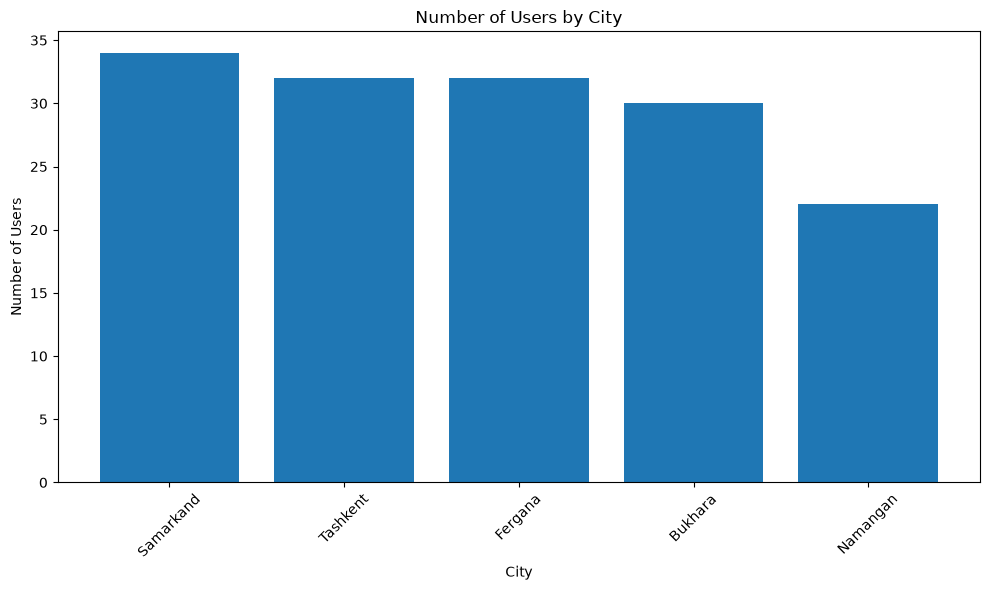

In [26]:
import matplotlib.pyplot as plt

city_counts = users_data['City'].value_counts()

plt.figure(figsize=(10, 6))

plt.bar(city_counts.index, city_counts.values)

plt.xlabel('City')
plt.ylabel('Number of Users')
plt.title('Number of Users by City')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


Q6. Phone Number RegEx Filter
Using Phone_Number column from users_data.csv and RegEx, filter phone numbers starting with +998(90). Note: in this dataset all 150 phone numbers follow the +998(90) format, so the result will be the full dataset. Use pattern: r'^\+998\(90\)' with re.match() or str.contains().

In [27]:
result = users_data[
    users_data['Phone_Number'].str.contains(r'^\+998\(90\)', regex=True)
]

result

,User_ID,Full_Name,Email,Phone_Number,Birth_Date,Join_Date,City
0,1001,User_0 Family_0,user0.test@provider.uz,+998(90)202-61-24,2003-05-02,2024-02-17,Tashkent
1,1002,User_1 Family_1,invalid_mail_1.com,+998(90)206-81-70,1992-05-26,2024-12-29,Fergana
2,1003,User_2 Family_2,user2.test@provider.uz,+998(90)120-92-96,1992-09-18,2025-10-17,Namangan
3,1004,User_3 Family_3,invalid_mail_3.com,+998(90)430-84-97,2009-03-29,2025-01-30,Tashkent
4,1005,User_4 Family_4,user4.test@provider.uz,+998(90)472-33-12,2010-08-01,2024-11-06,Fergana
...,...,...,...,...,...,...,...
145,1146,User_145 Family_145,invalid_mail_145.com,+998(90)413-67-95,1990-04-25,2025-04-06,Tashkent
146,1147,User_146 Family_146,user146.test@provider.uz,+998(90)404-61-51,1991-09-09,2025-03-05,Tashkent
147,1148,User_147 Family_147,invalid_mail_147.com,+998(90)937-24-63,2000-11-18,2024-11-19,Fergana
148,1149,User_148 Family_148,user148.test@provider.uz,+998(90)543-17-62,1998-12-12,2023-04-15,Namangan


Q7. Most Expensive Category
Using Product_Category and Unit_Price columns from sales_history.csv, find the category with highest average Unit_Price.

In [72]:
result = sales_history.groupby('Product_Category', as_index=False).agg(MaxUnitPrice = ('Unit_Price', 'mean'))

result

,Product_Category,MaxUnitPrice
0,Accessories,607.485714
1,Electronics,841.513514
2,Home Appliances,724.864865
3,Office Supplies,770.317073


Q8. Status Code Frequency
Using Status_Code column from technical_logs.csv, count frequency of each status code.

In [31]:
status_frequency = technical_logs['Status_Code'].value_counts()

status_frequency

Status_Code
200    115
201     13
404     10
500      7
400      5
Name: count, dtype: int64

Q9. Payment Method Pie Chart
Using Payment_Method column from sales_history.csv, create a pie chart showing payment distribution.

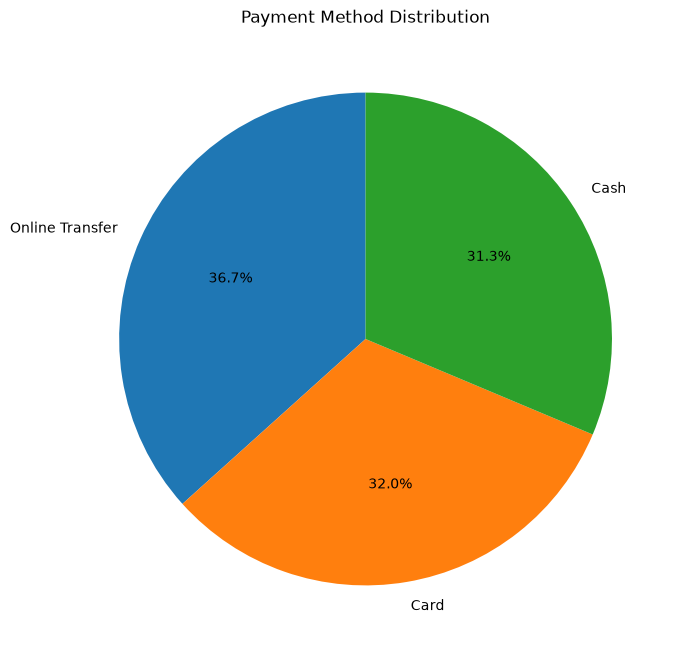

In [34]:
payment_counts = sales_history['Payment_Method'].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    payment_counts.values,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Payment Method Distribution')

plt.show()

Q10. Uppercase Names
Using Full_Name column from users_data.csv, convert all names to uppercase.

In [37]:
users_data['Full_Name'] = users_data['Full_Name'].str.upper()

users_data

,User_ID,Full_Name,Email,Phone_Number,Birth_Date,Join_Date,City
0,1001,USER_0 FAMILY_0,user0.test@provider.uz,+998(90)202-61-24,2003-05-02,2024-02-17,Tashkent
1,1002,USER_1 FAMILY_1,invalid_mail_1.com,+998(90)206-81-70,1992-05-26,2024-12-29,Fergana
2,1003,USER_2 FAMILY_2,user2.test@provider.uz,+998(90)120-92-96,1992-09-18,2025-10-17,Namangan
3,1004,USER_3 FAMILY_3,invalid_mail_3.com,+998(90)430-84-97,2009-03-29,2025-01-30,Tashkent
4,1005,USER_4 FAMILY_4,user4.test@provider.uz,+998(90)472-33-12,2010-08-01,2024-11-06,Fergana
...,...,...,...,...,...,...,...
145,1146,USER_145 FAMILY_145,invalid_mail_145.com,+998(90)413-67-95,1990-04-25,2025-04-06,Tashkent
146,1147,USER_146 FAMILY_146,user146.test@provider.uz,+998(90)404-61-51,1991-09-09,2025-03-05,Tashkent
147,1148,USER_147 FAMILY_147,invalid_mail_147.com,+998(90)937-24-63,2000-11-18,2024-11-19,Fergana
148,1149,USER_148 FAMILY_148,user148.test@provider.uz,+998(90)543-17-62,1998-12-12,2023-04-15,Namangan


### Medium Questions

Q11. Invalid Email Detection
Using Email column from users_data.csv and RegEx, identify invalid email addresses.

In [39]:
pattern = r'^[\w\.-]+@[\w\.-]+\.\w+$'

invalid_emails = users_data[
    ~users_data['Email'].str.match(pattern, na=False)
]

invalid_emails

,User_ID,Full_Name,Email,Phone_Number,Birth_Date,Join_Date,City
1,1002,USER_1 FAMILY_1,invalid_mail_1.com,+998(90)206-81-70,1992-05-26,2024-12-29,Fergana
3,1004,USER_3 FAMILY_3,invalid_mail_3.com,+998(90)430-84-97,2009-03-29,2025-01-30,Tashkent
5,1006,USER_5 FAMILY_5,invalid_mail_5.com,+998(90)761-62-11,2001-05-05,2024-04-01,Fergana
7,1008,USER_7 FAMILY_7,invalid_mail_7.com,+998(90)485-73-69,2009-01-27,2023-07-11,Fergana
9,1010,USER_9 FAMILY_9,invalid_mail_9.com,+998(90)413-31-98,2008-08-13,2025-09-04,Fergana
...,...,...,...,...,...,...,...
141,1142,USER_141 FAMILY_141,invalid_mail_141.com,+998(90)242-75-41,2009-06-23,2023-08-12,Tashkent
143,1144,USER_143 FAMILY_143,invalid_mail_143.com,+998(90)150-34-67,1998-05-28,2025-05-02,Samarkand
145,1146,USER_145 FAMILY_145,invalid_mail_145.com,+998(90)413-67-95,1990-04-25,2025-04-06,Tashkent
147,1148,USER_147 FAMILY_147,invalid_mail_147.com,+998(90)937-24-63,2000-11-18,2024-11-19,Fergana


Q12. Final Amount Calculation
Using Total_Price and Discount_Percent columns from sales_history.csv, create Final_Amount column after applying the discount: Final_Amount = Total_Price * (1 - Discount_Percent / 100)

In [40]:
sales_history['Final_Amount'] = sales_history['Total_Price'] * (1 - sales_history['Discount_Percent'] / 100)

sales_history

,Transaction_ID,User_ID,Product_Category,Quantity,Unit_Price,Discount_Percent,Payment_Method,Total_Price,Final_Amount
0,50001,1068,Home Appliances,5,60,24,Online Transfer,300,228.00
1,50002,1138,Electronics,1,725,15,Card,725,616.25
2,50003,1067,Office Supplies,7,1186,0,Card,8302,8302.00
3,50004,1109,Home Appliances,1,236,20,Online Transfer,236,188.80
4,50005,1146,Electronics,4,856,13,Card,3424,2978.88
...,...,...,...,...,...,...,...,...,...
145,50146,1038,Office Supplies,5,1215,15,Card,6075,5163.75
146,50147,1097,Home Appliances,4,425,7,Card,1700,1581.00
147,50148,1033,Home Appliances,3,373,27,Cash,1119,816.87
148,50149,1086,Accessories,5,195,0,Online Transfer,975,975.00


Q13. Monthly Revenue Analysis
column (Q12), then group by User_ID and calculate total Final_Amount per user as a monthly proxy analysis.


In [41]:
result = sales_history.groupby('User_ID', as_index=False).agg(Total_Final_Amount = ('Final_Amount', 'sum'))

result

,User_ID,Total_Final_Amount
0,1001,4884.39
1,1003,1486.03
2,1004,5856.00
3,1005,11306.64
4,1006,991.59
...,...,...
88,1142,576.00
89,1143,8505.18
90,1145,4386.48
91,1146,9378.24


Q14. Response Time Trend
Using Timestamp and Response_Time_ms columns from technical_logs.csv, create a line chart showing response time trend.

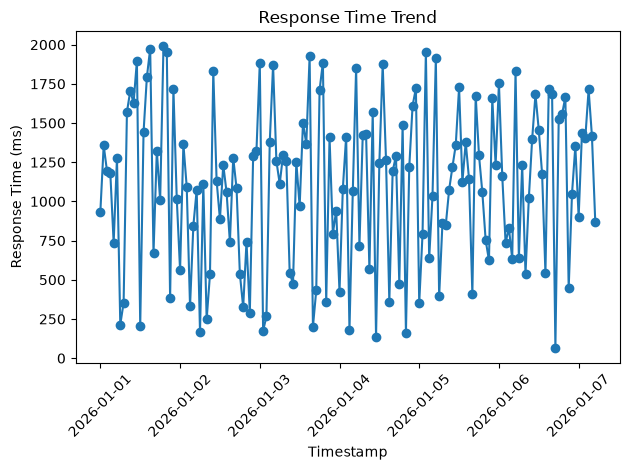

In [46]:
technical_logs['Timestamp'] = pd.to_datetime(
    technical_logs['Timestamp']
)

plt.plot(technical_logs['Timestamp'], technical_logs['Response_Time_ms'], marker='o')

plt.title("Response Time Trend")
plt.xlabel("Timestamp")
plt.ylabel("Response Time (ms)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Q15. Merge Users and Sales
Merge users_data.csv and sales_history.csv using User_ID column.

In [47]:
users_data.merge(sales_history, on='User_ID')

,User_ID,Full_Name,Email,Phone_Number,Birth_Date,Join_Date,City,Transaction_ID,Product_Category,Quantity,Unit_Price,Discount_Percent,Payment_Method,Total_Price,Final_Amount
0,1112,USER_111 FAMILY_111,invalid_mail_111.com,+998(90)982-95-31,1995-04-16,2024-11-06,Tashkent,50025,Home Appliances,2,203,23,Cash,406,312.62
1,1139,USER_138 FAMILY_138,user138.test@provider.uz,+998(90)135-54-29,2001-06-17,2024-01-09,Fergana,50068,Electronics,5,450,2,Online Transfer,2250,2205.00
2,1062,USER_61 FAMILY_61,invalid_mail_61.com,+998(90)430-98-71,1999-03-11,2023-12-05,Namangan,50029,Office Supplies,2,1090,1,Cash,2180,2158.20
3,1042,USER_41 FAMILY_41,invalid_mail_41.com,+998(90)127-16-82,2000-01-21,2025-11-28,Samarkand,50120,Home Appliances,5,463,27,Card,2315,1689.95
4,1062,USER_61 FAMILY_61,invalid_mail_61.com,+998(90)430-98-71,1999-03-11,2023-12-05,Namangan,50092,Accessories,9,669,27,Card,6021,4395.33
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,1067,USER_66 FAMILY_66,user66.test@provider.uz,+998(90)776-60-53,2003-12-23,2024-03-20,Namangan,50003,Office Supplies,7,1186,0,Card,8302,8302.00
146,1135,USER_134 FAMILY_134,user134.test@provider.uz,+998(90)576-51-35,1992-01-24,2025-03-08,Samarkand,50141,Accessories,5,1432,12,Online Transfer,7160,6300.80
147,1015,USER_14 FAMILY_14,user14.test@provider.uz,+998(90)975-64-73,1994-08-21,2023-10-06,Tashkent,50143,Electronics,6,438,5,Cash,2628,2496.60
148,1086,USER_85 FAMILY_85,invalid_mail_85.com,+998(90)863-68-45,2006-02-07,2025-04-03,Fergana,50149,Accessories,5,195,0,Online Transfer,975,975.00


Q16. JSON Parsing
Using Server_Message column from technical_logs.csv, parse JSON strings and extract request_id into a new column. Note: request_id only exists in success rows (status: success). Use .get('request_id', None) to handle rows where it is missing — other rows contain error/code keys instead.

In [49]:
import json

technical_logs['request_id'] = technical_logs['Server_Message'].apply(
    lambda x: json.loads(x).get('request_id', None)
)

technical_logs[['Server_Message', 'request_id']]

,Server_Message,request_id
0,"{""status"": ""success"", ""request_id"": 0}",0.0
1,"{""error"": ""not_found"", ""code"": 404}",NaN
2,"{""status"": ""success"", ""request_id"": 2}",2.0
3,"{""error"": ""not_found"", ""code"": 404}",NaN
4,"{""status"": ""success"", ""request_id"": 4}",4.0
...,...,...
145,"{""error"": ""not_found"", ""code"": 404}",NaN
146,"{""status"": ""success"", ""request_id"": 146}",146.0
147,"{""error"": ""not_found"", ""code"": 404}",NaN
148,"{""status"": ""success"", ""request_id"": 148}",148.0


Q17. User Age Histogram
Using Birth_Date column from users_data.csv, calculate user ages and create a histogram.

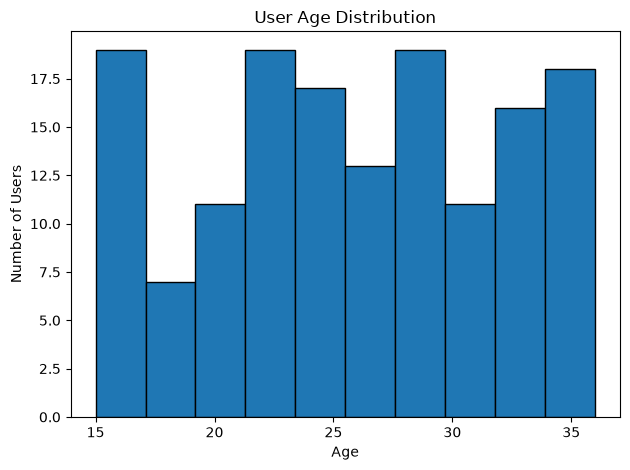

In [51]:
from datetime import datetime

# Birth_Date ni datetime formatga o'tkazamiz
users_data['Birth_Date'] = pd.to_datetime(users_data['Birth_Date'])

# Hozirgi yil
today = pd.Timestamp.now()

# Yoshni hisoblash
users_data['Age'] = (
    today.year - users_data['Birth_Date'].dt.year
)

users_data.loc[
    (
        users_data['Birth_Date'].dt.month > today.month
    ) |
    (
        (users_data['Birth_Date'].dt.month == today.month) &
        (users_data['Birth_Date'].dt.day > today.day)
    ),
    'Age'
] -= 1

# Histogram
plt.hist(users_data['Age'], bins=10, edgecolor='black')

plt.title('User Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Users')

plt.tight_layout()
plt.show()

Q18. Weekend Transactions. Using Discount_Percent column, filter transactions where Discount_Percent >= 20 as a high-discount analysis.

In [52]:
high_discount = sales_history[
    sales_history['Discount_Percent'] >= 20
]

high_discount

,Transaction_ID,User_ID,Product_Category,Quantity,Unit_Price,Discount_Percent,Payment_Method,Total_Price,Final_Amount
0,50001,1068,Home Appliances,5,60,24,Online Transfer,300,228.00
3,50004,1109,Home Appliances,1,236,20,Online Transfer,236,188.80
9,50010,1008,Office Supplies,6,104,24,Online Transfer,624,474.24
10,50011,1113,Accessories,8,672,23,Cash,5376,4139.52
13,50014,1101,Accessories,1,455,26,Online Transfer,455,336.70
14,50015,1006,Accessories,7,118,25,Card,826,619.50
16,50017,1064,Electronics,8,1362,28,Card,10896,7845.12
19,50020,1121,Electronics,8,1317,27,Online Transfer,10536,7691.28
22,50023,1021,Accessories,1,531,23,Online Transfer,531,408.87
24,50025,1112,Home Appliances,2,203,23,Cash,406,312.62


Q19. Top Transaction Users
Using User_ID column from sales_history.csv, identify top 3 users with highest number of transactions.

In [55]:
top_users = (
    sales_history['User_ID']
    .value_counts()
    .head(3)
)

top_users

User_ID
1111    4
1064    4
1094    4
Name: count, dtype: int64

Q20. Category Box Plot
Using Product_Category and Unit_Price columns from sales_history.csv, create a box plot comparing Unit_Price distributions.

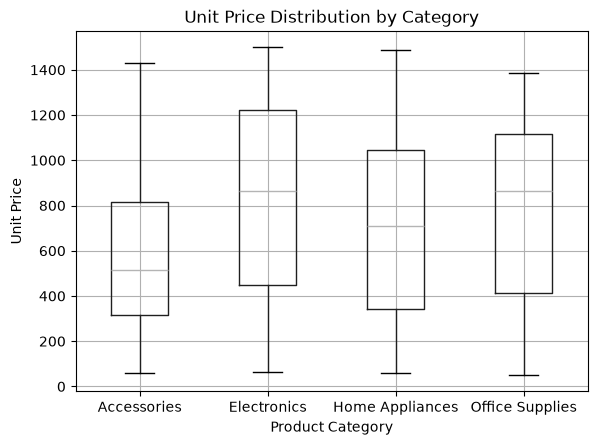

In [56]:
sales_history.boxplot(
    column='Unit_Price',
    by='Product_Category'
)

plt.title('Unit Price Distribution by Category')
plt.xlabel('Product Category')
plt.ylabel('Unit Price')

plt.suptitle('')  # Pandas yaratgan qo'shimcha title ni olib tashlaydi

plt.show()

### Hard Questions

Q21. User Validation & Cleaning Intelligence System — Using users_data.csv, validate emails, normalize phone numbers using RegEx, calculate user ages using datetime, detect invalid records, identify duplicated contacts, and export clean_users.csv.

In [58]:
import re


# =========================================================
# 1. EMAIL VALIDATION
# =========================================================

email_pattern = r'^[\w\.-]+@[\w\.-]+\.\w+$'

users_data['Email_Valid'] = users_data['Email'].str.match(
    email_pattern,
    na=False
)


# =========================================================
# 2. PHONE NUMBER NORMALIZATION
# =========================================================

def normalize_phone(phone):
    phone = str(phone)

    # Faqat raqamlarni qoldiramiz
    digits = re.sub(r'\D', '', phone)

    # 998 bilan boshlansa
    if digits.startswith('998'):
        return '+' + digits

    # 90 bilan boshlansa
    elif digits.startswith('90'):
        return '+998' + digits

    return None


users_data['Phone_Number_Clean'] = (
    users_data['Phone_Number']
    .apply(normalize_phone)
)


# =========================================================
# 3. CALCULATE AGE
# =========================================================

users_data['Birth_Date'] = pd.to_datetime(
    users_data['Birth_Date'],
    errors='coerce'
)

today = pd.Timestamp.now()

users_data['Age'] = (
    today.year - users_data['Birth_Date'].dt.year
)

# Tug'ilgan kun hali kelmagan bo'lsa 1 ayiramiz
birthday_not_reached = (
    (users_data['Birth_Date'].dt.month > today.month)
    |
    (
        (users_data['Birth_Date'].dt.month == today.month)
        &
        (users_data['Birth_Date'].dt.day > today.day)
    )
)

users_data.loc[birthday_not_reached, 'Age'] -= 1


# =========================================================
# 4. INVALID RECORDS
# =========================================================

users_data['Invalid_Record'] = (
    ~users_data['Email_Valid']
    |
    users_data['Phone_Number_Clean'].isna()
    |
    users_data['Age'].isna()
)


invalid_users = users_data[
    users_data['Invalid_Record']
]

print("Invalid users:")
print(invalid_users)


# =========================================================
# 5. DUPLICATED CONTACTS
# =========================================================

users_data['Duplicate_Contact'] = (
    users_data.duplicated(
        subset=['Email', 'Phone_Number_Clean'],
        keep=False
    )
)

duplicated_contacts = users_data[
    users_data['Duplicate_Contact']
]

print("\nDuplicated contacts:")
print(duplicated_contacts)


# =========================================================
# 6. CLEAN DATA
# =========================================================

clean_users = users_data[
    (~users_data['Invalid_Record'])
    &
    (~users_data['Duplicate_Contact'])
].copy()


# Keraksiz yordamchi ustunlarni olib tashlaymiz
clean_users = clean_users.drop(
    columns=[
        'Email_Valid',
        'Invalid_Record',
        'Duplicate_Contact',
        'Phone_Number'
    ],
    errors='ignore'
)

# Phone_Number_Clean ni Phone_Number deb nomlaymiz
clean_users = clean_users.rename(
    columns={
        'Phone_Number_Clean': 'Phone_Number'
    }
)


# =========================================================
# 7. EXPORT
# =========================================================

clean_users.to_csv(
    'clean_users.csv',
    index=False
)

print("\nClean data exported successfully!")
print(f"Clean users count: {len(clean_users)}")

Invalid users:
     User_ID            Full_Name                 Email       Phone_Number  \
1       1002      USER_1 FAMILY_1    invalid_mail_1.com  +998(90)206-81-70   
3       1004      USER_3 FAMILY_3    invalid_mail_3.com  +998(90)430-84-97   
5       1006      USER_5 FAMILY_5    invalid_mail_5.com  +998(90)761-62-11   
7       1008      USER_7 FAMILY_7    invalid_mail_7.com  +998(90)485-73-69   
9       1010      USER_9 FAMILY_9    invalid_mail_9.com  +998(90)413-31-98   
..       ...                  ...                   ...                ...   
141     1142  USER_141 FAMILY_141  invalid_mail_141.com  +998(90)242-75-41   
143     1144  USER_143 FAMILY_143  invalid_mail_143.com  +998(90)150-34-67   
145     1146  USER_145 FAMILY_145  invalid_mail_145.com  +998(90)413-67-95   
147     1148  USER_147 FAMILY_147  invalid_mail_147.com  +998(90)937-24-63   
149     1150  USER_149 FAMILY_149  invalid_mail_149.com  +998(90)671-14-77   

    Birth_Date  Join_Date       City  Age  Email

Q22. Sales & User Intelligence Dashboard — Using users_data.csv and sales_history.csv, merge datasets using User_ID, calculate city-level revenue, identify loyal users with Total Spending > 5000, calculate average transaction value, visualize city revenue, and export loyal_users_report.json.

City Revenue:
        City  Total_Price
0    Bukhara        86384
1    Fergana        95200
2   Namangan        97409
3  Samarkand       100663
4   Tashkent       142151

Loyal Users:
    User_ID            Full_Name       City  Total_Price
0      1001      USER_0 FAMILY_0   Tashkent         5058
2      1004      USER_3 FAMILY_3   Tashkent         6649
3      1005      USER_4 FAMILY_4    Fergana        13740
8      1011    USER_10 FAMILY_10    Fergana         7760
10     1014    USER_13 FAMILY_13    Bukhara        14706
17     1026    USER_25 FAMILY_25   Namangan        15283
19     1031    USER_30 FAMILY_30    Bukhara         7784
22     1034    USER_33 FAMILY_33   Tashkent         5532
23     1035    USER_34 FAMILY_34   Namangan        11132
25     1037    USER_36 FAMILY_36    Bukhara         5445
26     1038    USER_37 FAMILY_37   Tashkent        14031
28     1040    USER_39 FAMILY_39    Fergana        10400
29     1042    USER_41 FAMILY_41  Samarkand         8742
32     1049    USE

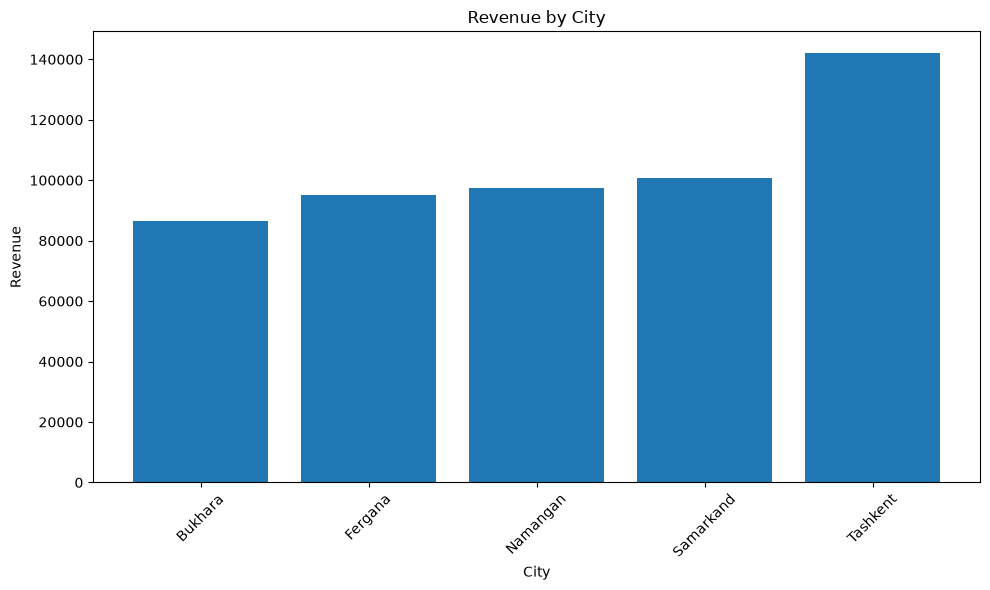


loyal_users_report.json created successfully!


In [66]:
# 1. User_ID orqali merge qilish
merged_data = users_data.merge(
    sales_history,
    on='User_ID',
    how='inner'
)


# 2. City-level revenue
city_revenue = (
    merged_data
    .groupby('City', as_index=False)['Total_Price']
    .sum()
)

print("City Revenue:")
print(city_revenue)


# 3. User bo'yicha umumiy spending
user_spending = (
    merged_data
    .groupby(
        ['User_ID', 'Full_Name', 'City'],
        as_index=False
    )['Total_Price']
    .sum()
)


# 4. Loyal users
loyal_users = user_spending[
    user_spending['Total_Price'] > 5000
]

print("\nLoyal Users:")
print(loyal_users)


# 5. Average transaction value
average_transaction_value = (
    sales_history['Total_Price'].mean()
)

print(
    "\nAverage Transaction Value:",
    average_transaction_value
)


# 6. City Revenue visualization
plt.figure(figsize=(10, 6))

plt.bar(
    city_revenue['City'],
    city_revenue['Total_Price']
)

plt.title('Revenue by City')
plt.xlabel('City')
plt.ylabel('Revenue')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# 7. Export loyal users report
loyal_users.to_json(
    'loyal_users_report.json',
    orient='records',
    indent=4
)

print("\nloyal_users_report.json created successfully!")

Q23. Technical Monitoring & Error Intelligence Analyzer — Using technical_logs.csv, analyze response times, detect slow requests where Response_Time_ms exceeds average response time, calculate error percentages for 400/404/500 codes, visualize response trends, and export technical_monitoring_report.csv.

Average Response Time: 1097.24 ms

Slow Requests:
     Log_ID           Timestamp  Status_Code  Response_Time_ms  \
1         2 2026-01-01 01:00:00          200              1357   
2         3 2026-01-01 02:00:00          200              1194   
3         4 2026-01-01 03:00:00          200              1180   
5         6 2026-01-01 05:00:00          200              1277   
8         9 2026-01-01 08:00:00          200              1570   
..      ...                 ...          ...               ...   
143     144 2026-01-06 23:00:00          200              1352   
145     146 2026-01-07 01:00:00          200              1438   
146     147 2026-01-07 02:00:00          200              1404   
147     148 2026-01-07 03:00:00          200              1714   
148     149 2026-01-07 04:00:00          404              1417   

                               Server_Message  request_id  
1         {"error": "not_found", "code": 404}         NaN  
2      {"status": "success", "request

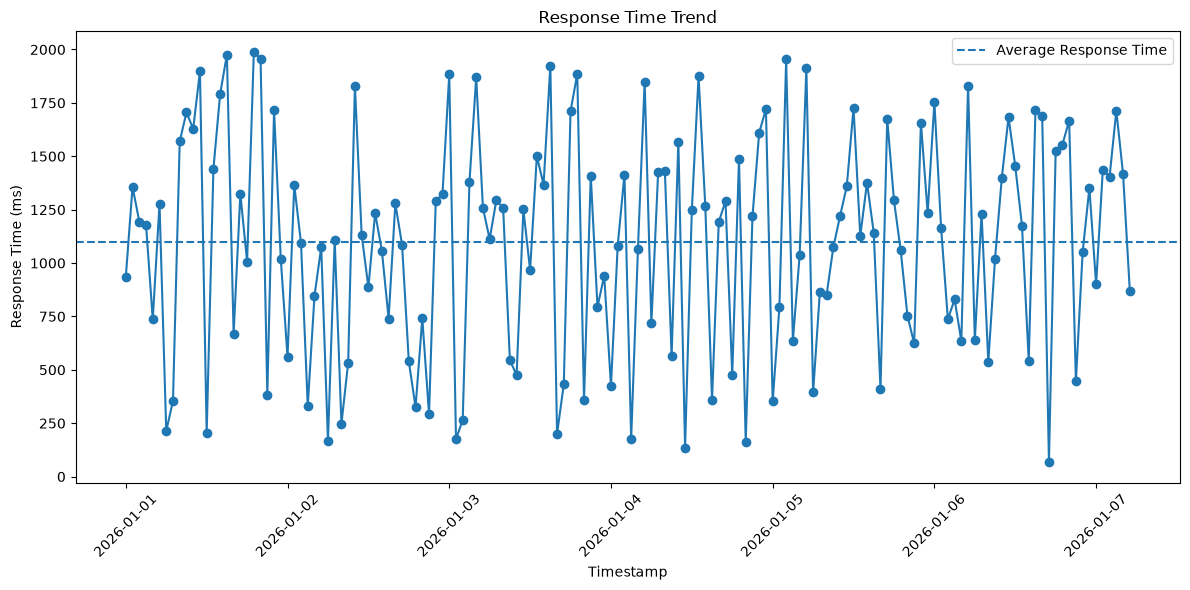


technical_monitoring_report.csv created successfully!


In [67]:
# =====================================================
# 2. Convert Timestamp
# =====================================================

technical_logs['Timestamp'] = pd.to_datetime(
    technical_logs['Timestamp']
)


# =====================================================
# 3. Average Response Time
# =====================================================

average_response_time = (
    technical_logs['Response_Time_ms'].mean()
)

print(
    f"Average Response Time: "
    f"{average_response_time:.2f} ms"
)


# =====================================================
# 4. Detect Slow Requests
# =====================================================

slow_requests = technical_logs[
    technical_logs['Response_Time_ms']
    > average_response_time
]

print("\nSlow Requests:")
print(slow_requests)


# =====================================================
# 5. Detect Errors
# =====================================================

total_logs = len(technical_logs)

error_logs = technical_logs[
    technical_logs['Status_Code']
    .isin([400, 404, 500])
]


# =====================================================
# 6. Error Percentage
# =====================================================

error_percentage = (
    len(error_logs) / total_logs
) * 100

print(
    f"\nTotal Error Percentage: "
    f"{error_percentage:.2f}%"
)


# Individual error percentages

print("\nError Percentages:")

for code in [400, 404, 500]:

    count = (
        technical_logs['Status_Code'] == code
    ).sum()

    percentage = (
        count / total_logs
    ) * 100

    print(
        f"{code}: "
        f"{count} logs "
        f"({percentage:.2f}%)"
    )


# =====================================================
# 7. Add Monitoring Columns
# =====================================================

technical_logs['Is_Slow_Request'] = (
    technical_logs['Response_Time_ms']
    > average_response_time
)

technical_logs['Is_Error'] = (
    technical_logs['Status_Code']
    .isin([400, 404, 500])
)


# =====================================================
# 8. Response Time Visualization
# =====================================================

plt.figure(figsize=(12, 6))

plt.plot(
    technical_logs['Timestamp'],
    technical_logs['Response_Time_ms'],
    marker='o'
)

plt.axhline(
    average_response_time,
    linestyle='--',
    label='Average Response Time'
)

plt.title('Response Time Trend')
plt.xlabel('Timestamp')
plt.ylabel('Response Time (ms)')

plt.xticks(rotation=45)

plt.legend()
plt.tight_layout()
plt.show()


# =====================================================
# 9. Export Report
# =====================================================

technical_monitoring_report = technical_logs[
    [
        'Timestamp',
        'Status_Code',
        'Response_Time_ms',
        'Is_Slow_Request',
        'Is_Error'
    ]
]

technical_monitoring_report.to_csv(
    'technical_monitoring_report.csv',
    index=False
)

print(
    "\ntechnical_monitoring_report.csv "
    "created successfully!"
)

Q24. Advanced Subplots Dashboard
Create a 2x2 subplot figure showing:

1. Total revenue by Product_Category (bar chart, from sales_history.csv)
2. User city distribution (bar chart, from users_data.csv)
3. Average Unit_Price by Product_Category (bar chart, from sales_history.csv)
4. User age histogram (from Birth_Date in users_data.csv)

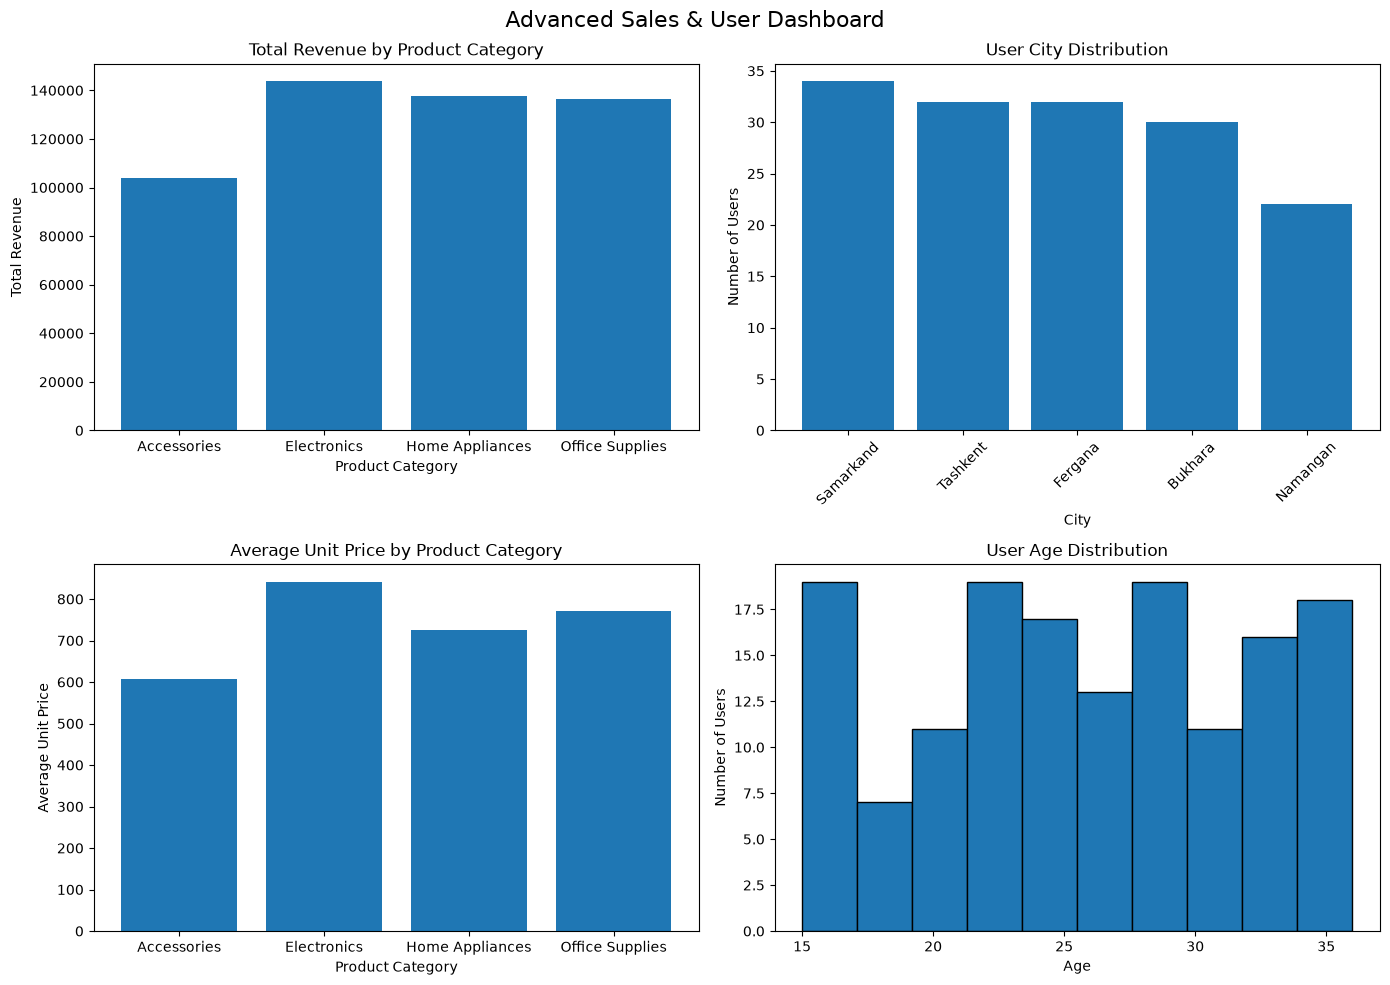

In [69]:
# =====================================================
# 1. Total Revenue by Product_Category
# =====================================================

revenue_by_category = (
    sales_history
    .groupby('Product_Category')['Total_Price']
    .sum()
)


# =====================================================
# 2. User City Distribution
# =====================================================

city_distribution = (
    users_data['City']
    .value_counts()
)


# =====================================================
# 3. Average Unit_Price by Product_Category
# =====================================================

avg_price_by_category = (
    sales_history
    .groupby('Product_Category')['Unit_Price']
    .mean()
)


# =====================================================
# 4. Calculate User Age
# =====================================================

users_data['Birth_Date'] = pd.to_datetime(
    users_data['Birth_Date']
)

today = pd.Timestamp.now()

users_data['Age'] = (
    today.year - users_data['Birth_Date'].dt.year
)

birthday_not_reached = (
    (users_data['Birth_Date'].dt.month > today.month)
    |
    (
        (users_data['Birth_Date'].dt.month == today.month)
        &
        (users_data['Birth_Date'].dt.day > today.day)
    )
)

users_data.loc[birthday_not_reached, 'Age'] -= 1


# =====================================================
# 5. Create 2x2 Subplots
# =====================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)


# =====================================================
# 6. Chart 1 - Revenue
# =====================================================

axes[0, 0].bar(
    revenue_by_category.index,
    revenue_by_category.values
)

axes[0, 0].set_title(
    'Total Revenue by Product Category'
)

axes[0, 0].set_xlabel(
    'Product Category'
)

axes[0, 0].set_ylabel(
    'Total Revenue'
)


# =====================================================
# 7. Chart 2 - City Distribution
# =====================================================

axes[0, 1].bar(
    city_distribution.index,
    city_distribution.values
)

axes[0, 1].set_title(
    'User City Distribution'
)

axes[0, 1].set_xlabel(
    'City'
)

axes[0, 1].set_ylabel(
    'Number of Users'
)

axes[0, 1].tick_params(
    axis='x',
    rotation=45
)


# =====================================================
# 8. Chart 3 - Average Unit Price
# =====================================================

axes[1, 0].bar(
    avg_price_by_category.index,
    avg_price_by_category.values
)

axes[1, 0].set_title(
    'Average Unit Price by Product Category'
)

axes[1, 0].set_xlabel(
    'Product Category'
)

axes[1, 0].set_ylabel(
    'Average Unit Price'
)


# =====================================================
# 9. Chart 4 - Age Histogram
# =====================================================

axes[1, 1].hist(
    users_data['Age'],
    bins=10,
    edgecolor='black'
)

axes[1, 1].set_title(
    'User Age Distribution'
)

axes[1, 1].set_xlabel(
    'Age'
)

axes[1, 1].set_ylabel(
    'Number of Users'
)


# =====================================================
# 10. Dashboard title and layout
# =====================================================

fig.suptitle(
    'Advanced Sales & User Dashboard',
    fontsize=16
)

plt.tight_layout()

plt.show()

Q25. Loyal Users Automation
Identify users who:

- joined in 2023
- spent more than 5000 total

Export their data into loyal_users.json.

In [71]:
# 1. User_ID bo'yicha umumiy spending
user_spending = (
    sales_history
    .groupby('User_ID', as_index=False)['Total_Price']
    .sum()
)


# 2. Users va spending ma'lumotlarini birlashtirish
merged_data = users_data.merge(
    user_spending,
    on='User_ID',
    how='inner'
)


# 3. Join_Date ni datetime formatga o'tkazish
merged_data['Join_Date'] = pd.to_datetime(
    merged_data['Join_Date']
)


# 4. 2023-yilda qo'shilgan va 5000 dan ko'p
loyal_users = merged_data[
    (merged_data['Join_Date'].dt.year == 2023)
    &
    (merged_data['Total_Price'] > 5000)
]


# 5. JSON faylga eksport
loyal_users.to_json(
    'loyal_users.json',
    orient='records',
    indent=4,
    date_format='iso'
)

print("loyal_users.json created successfully!")
print(loyal_users)

loyal_users.json created successfully!
    User_ID            Full_Name                     Email       Phone_Number  \
10     1014    USER_13 FAMILY_13       invalid_mail_13.com  +998(90)786-71-60   
22     1034    USER_33 FAMILY_33       invalid_mail_33.com  +998(90)316-69-50   
32     1049    USER_48 FAMILY_48   user48.test@provider.uz  +998(90)104-23-36   
37     1062    USER_61 FAMILY_61       invalid_mail_61.com  +998(90)430-98-71   
44     1069    USER_68 FAMILY_68   user68.test@provider.uz  +998(90)473-41-97   
45     1070    USER_69 FAMILY_69       invalid_mail_69.com  +998(90)332-61-71   
46     1072    USER_71 FAMILY_71       invalid_mail_71.com  +998(90)367-48-11   
53     1083    USER_82 FAMILY_82   user82.test@provider.uz  +998(90)610-25-82   
60     1095    USER_94 FAMILY_94   user94.test@provider.uz  +998(90)980-11-10   
69     1113  USER_112 FAMILY_112  user112.test@provider.uz  +998(90)849-39-47   
71     1118  USER_117 FAMILY_117      invalid_mail_117.com  +998(90)58